# K-Means trên tập feature A (RFM) đã tiền xử lý

Notebook sử dụng nguyên dữ liệu đầu vào; chỉ fit StandardScaler, PCA và K-Means. Kết quả mô tả hành vi mua trong lịch sử, chưa phải dự báo giá trị khách hàng tương lai.

## feature A (RFM)

## Params

In [25]:
RANDOM_STATE = 42
INIT = "k-means++"
N_INIT = 10
MAX_ITER = 300
TOL = 1e-4

## import thư viện

In [26]:
import json
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

In [27]:
# Chạy từ thư mục notebook, project/ hoặc gốc repository.
relative_dir = Path('notebooks/02_baseline_kmeans/17-11-2026-hieu-kmeans-rfm')
candidates = [Path.cwd(), Path.cwd() / relative_dir, Path.cwd() / 'project' / relative_dir]
BASE_DIR = next((p for p in candidates if (p / 'data/customer_features.csv').is_file()), None)
if BASE_DIR is None:
    raise FileNotFoundError('Không tìm thấy data/customer_features.csv của notebook.')
FIGURES_DIR = BASE_DIR / 'figures'
FIGURES_DIR.mkdir(exist_ok=True)
df = pd.read_csv(BASE_DIR / 'data/customer_features.csv', dtype={'CustomerID': 'string'})
FEATURE_A = ['Recency', 'Frequency', 'Monetary']
X = df[FEATURE_A].copy()
display(X.head())

,Recency,Frequency,Monetary
0,3,7,4310.00
1,76,4,1437.24
2,19,1,1457.55
3,311,1,294.40
4,37,7,1385.74


## Kiểm tra đầu vào (không thay đổi dữ liệu đã tiền xử lý)

In [28]:
display(X.isna().sum().rename('Số giá trị thiếu'))
assert df['CustomerID'].notna().all(), 'CustomerID bị thiếu.'
assert df['CustomerID'].is_unique, 'Cần một dòng cho mỗi CustomerID.'
assert len(X) >= 3, 'Cần ít nhất 3 khách hàng để khảo sát k.'
assert all(pd.api.types.is_numeric_dtype(X[c]) for c in FEATURE_A), 'RFM phải là số.'
assert np.isfinite(X.to_numpy(dtype=float)).all(), 'RFM có missing hoặc giá trị vô hạn.'
assert X['Recency'].ge(0).all(), 'Recency phải không âm.'
assert X['Frequency'].gt(0).all(), 'Frequency phải dương.'
assert X['Monetary'].gt(0).all(), 'Monetary phải dương trong tập mua RFM này.'

Recency      0
Frequency    0
Monetary     0
Name: Số giá trị thiếu, dtype: int64

In [29]:
# Một cấu hình chung cho cả khảo sát k và mô hình cuối.
KMEANS_PARAMS = dict(random_state=RANDOM_STATE, init=INIT, n_init=N_INIT,
                     max_iter=MAX_ITER, tol=TOL)

## Scaling lại dữ liệu

* Do Monetary có giá trị lớn hơn rất nhiều so với Recency và Frequency nên Monetary gần như quyết định toàn bộ khoảng cách giữa các khách hàng.
* Hậu quả là K-Means có thể phân cụm chủ yếu dựa trên số tiền chi tiêu, trong khi Recency và Frequency ít ảnh hưởng đến kết quả.

In [30]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

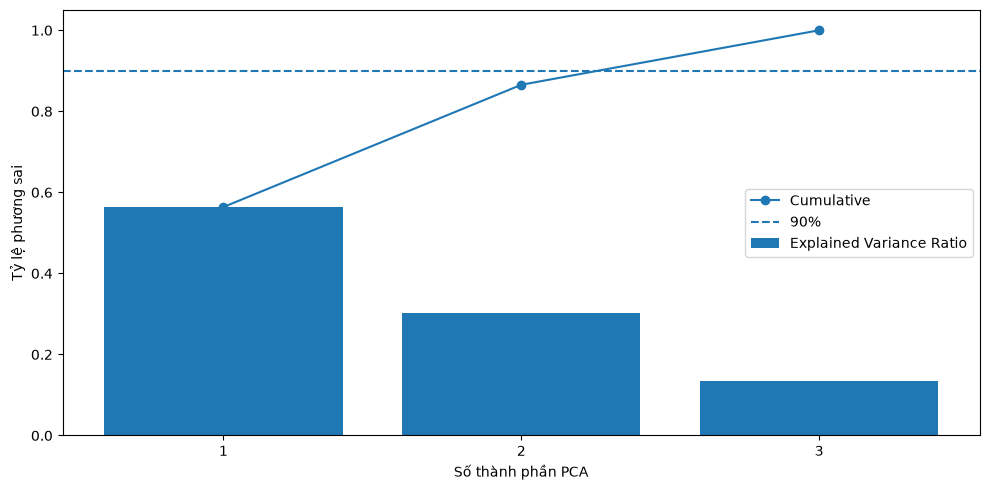

In [31]:
pca_full = PCA(svd_solver="full")
pca_full.fit(X_scaled)
variance = pca_full.explained_variance_ratio_
cumulative = np.cumsum(variance)
components = np.arange(1, len(variance) + 1)
threshold = 0.90

plt.figure(figsize=(10, 5))
plt.plot(components, cumulative, marker="o", label="Cumulative")
plt.axhline(threshold, color="tab:blue", linestyle="--", label=f"{threshold:.0%}")
plt.bar(components, variance, label="Explained Variance Ratio")
plt.xlabel("Số thành phần PCA")
plt.ylabel("Tỷ lệ phương sai")
plt.xticks(components)
plt.ylim(0, 1.05)
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "PCA.png", dpi=300, bbox_inches="tight")
plt.show()

n_components = int(np.searchsorted(cumulative, threshold) + 1)

## PCA giữ tối thiểu 90% phương sai

Nếu phải giữ cả ba thành phần thì PCA chỉ đổi hệ trục, không giảm số chiều. StandardScaler không loại bỏ ảnh hưởng của ngoại lệ; cần xem thêm kích thước và hồ sơ cụm khi diễn giải.

In [32]:
pca_features = PCA(n_components=n_components, svd_solver='full')
X_pca = pca_features.fit_transform(X_scaled)
assert X_pca.shape == (X_scaled.shape[0], n_components)
assert np.isfinite(X_pca).all()
assert pca_features.explained_variance_ratio_.sum() >= threshold - 1e-12
print('Số chiều PCA:', n_components)
print('Phương sai giữ lại:', pca_features.explained_variance_ratio_.sum())
print('Đã giảm chiều.' if n_components < X.shape[1] else 'Giữ đủ các chiều; PCA chỉ đổi hệ trục.')

Số chiều PCA: 3
Phương sai giữ lại: 0.9999999999999999
Giữ đủ các chiều; PCA chỉ đổi hệ trục.


In [33]:
results = []
candidate_models = {}
max_k = min(10, len(X_pca) - 1, len(np.unique(X_pca, axis=0)))
for k in range(2, max_k + 1):
    candidate = KMeans(n_clusters=k, **KMEANS_PARAMS)
    candidate_labels = candidate.fit_predict(X_pca)
    if not 2 <= len(np.unique(candidate_labels)) < len(X_pca):
        continue
    candidate_models[k] = candidate
    results.append({
        'k': k,
        'Silhouette': silhouette_score(X_pca, candidate_labels),
        'DBI': davies_bouldin_score(X_pca, candidate_labels),
        'CHI': calinski_harabasz_score(X_pca, candidate_labels),
        'Inertia': candidate.inertia_,
    })
if not results:
    raise ValueError('Không có phương án k hợp lệ để đánh giá.')
metrics = pd.DataFrame(results)
display(metrics.round(4))

,k,Silhouette,DBI,CHI,Inertia
0,2,0.8994,0.7275,1947.5218,8950.5986
1,3,0.5921,0.6944,3052.7379,5381.8486
2,4,0.6158,0.7416,3209.0488,4022.6720
3,5,0.6001,0.6539,3590.5747,3002.7288
4,6,0.5975,0.5946,3911.0777,2349.2241
5,7,0.5196,0.6043,4210.6281,1895.6172
6,8,0.4792,0.6633,4461.3181,1577.1689
7,9,0.4792,0.6926,4705.2462,1335.8449
8,10,0.4236,0.7133,4797.9135,1179.8267


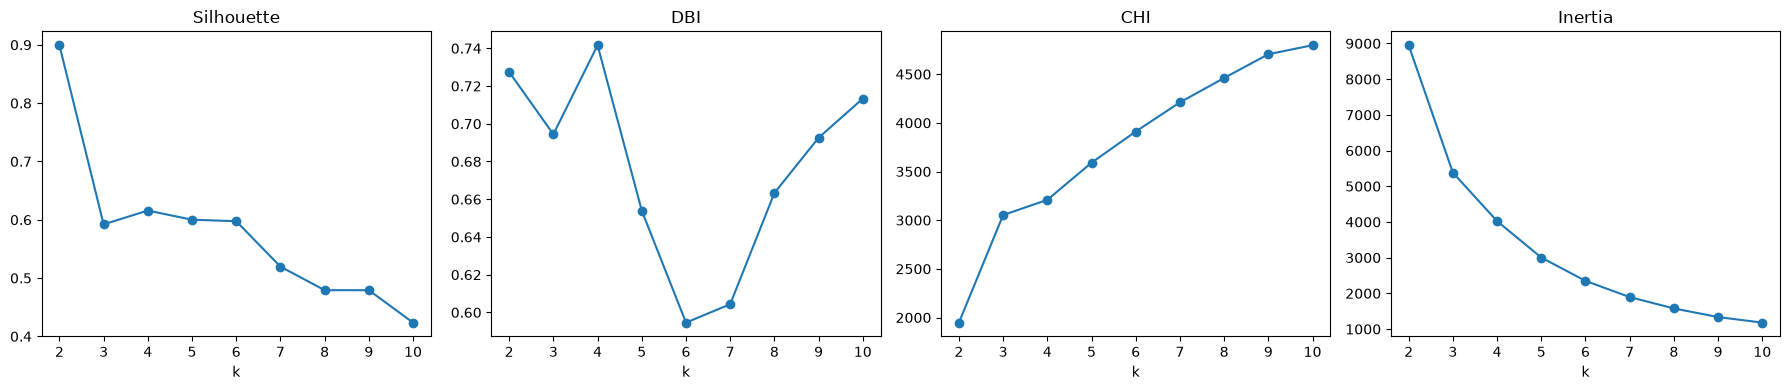

K đề xuất theo Silhouette trong phạm vi khảo sát: 2


In [34]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, ['Silhouette', 'DBI', 'CHI', 'Inertia']):
    ax.plot(metrics['k'], metrics[col], marker='o')
    ax.set_xlabel('k')
    ax.set_title(col)
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'kmeans_metrics.png', dpi=300, bbox_inches='tight')
plt.show()
best_k = int(metrics.loc[metrics['Silhouette'].idxmax(), 'k'])
print('K đề xuất theo Silhouette trong phạm vi khảo sát:', best_k)

In [ ]:
best_row = metrics.loc[metrics['k'].eq(best_k)].iloc[0]
dbi_k = int(metrics.loc[metrics['DBI'].idxmin(), 'k'])
chi_k = int(metrics.loc[metrics['CHI'].idxmax(), 'k'])

Chọn **k=2** theo Silhouette lớn nhất (0.8994) trong phạm vi khảo sát. DBI thấp nhất ở k=6; CHI cao nhất ở k=10. Các chỉ số đều tính trên dữ liệu PCA dùng để fit K-Means. Đây là đánh giá nội bộ trên cùng tập khách hàng; cần kết hợp Elbow, kích thước và hồ sơ cụm, chưa khẳng định k tối ưu tuyệt đối.

**k=2** theo Silhouette lớn nhất 0.8994 
trong phạm vi khảo sát. DBI thấp nhất ở k=6; CHI cao nhất ở k=10.
Các chỉ số đều tính trên dữ liệu PCA dùng để fit K-Means.
Đây là đánh giá nội bộ trên cùng tập khách hàng; cần kết hợp Elbow, kích thước 
và hồ sơ cụm, chưa khẳng định k tối ưu tuyệt đối.

## Dùng mô hình tốt nhất đã fit trong vòng khảo sát

In [36]:
# Tái sử dụng đúng mô hình được chấm điểm, không fit lại trên RFM gốc.
model = candidate_models[best_k]
labels = model.labels_.copy()
assert np.array_equal(model.predict(X_pca), labels)

In [37]:
result = df[['CustomerID'] + FEATURE_A].copy()
result['cluster'] = labels
print('Số lượng theo cụm:')
display(result['cluster'].value_counts().sort_index())
display(result.head())

Số lượng theo cụm:


cluster
0    4303
1      24
Name: count, dtype: int64

,CustomerID,Recency,Frequency,Monetary,cluster
0,12347,3,7,4310.00,0
1,12348,76,4,1437.24,0
2,12349,19,1,1457.55,0
3,12350,311,1,294.40,0
4,12352,37,7,1385.74,0


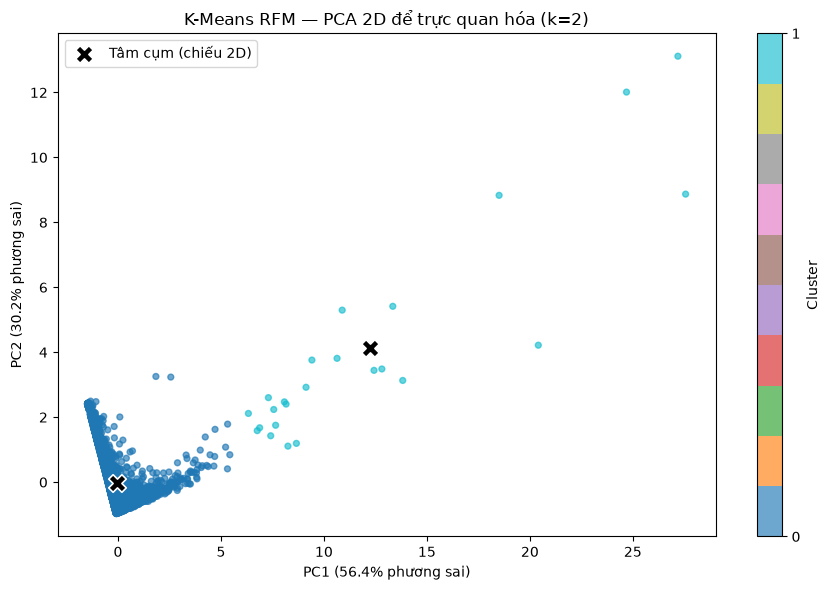

In [38]:
# PCA riêng cho hình vẽ, không thay đổi PCA đầu vào của mô hình.
pca_plot = PCA(n_components=2, svd_solver='full')
coords = pca_plot.fit_transform(X_scaled)
centers_scaled = pca_features.inverse_transform(model.cluster_centers_)
centers_2d = pca_plot.transform(centers_scaled)
fig, ax = plt.subplots(figsize=(9, 6))
scatter = ax.scatter(coords[:, 0], coords[:, 1], c=labels,
                     cmap='tab10', s=18, alpha=0.65, rasterized=True)
ax.scatter(centers_2d[:, 0], centers_2d[:, 1], c='black', marker='X', s=160,
           edgecolors='white', linewidths=1.2, label='Tâm cụm (chiếu 2D)')
ax.set_title(f'K-Means RFM — PCA 2D để trực quan hóa (k={best_k})')
ax.set_xlabel(f'PC1 ({pca_plot.explained_variance_ratio_[0]:.1%} phương sai)')
ax.set_ylabel(f'PC2 ({pca_plot.explained_variance_ratio_[1]:.1%} phương sai)')
ax.legend(loc='best')
fig.colorbar(scatter, ax=ax, label='Cluster', ticks=sorted(np.unique(labels)))
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'kmeans_clusters_pca.png', dpi=300, bbox_inches='tight')
plt.show()

In [39]:
cluster_count = pd.Series(labels).value_counts().sort_index()

cluster_summary = pd.DataFrame({
    "Số khách hàng": cluster_count,
    "Tỷ lệ (%)": (cluster_count / len(labels) * 100).round(2)
})

display(cluster_summary)

,Số khách hàng,Tỷ lệ (%)
0,4303,99.45
1,24,0.55


In [40]:
cluster_medians = result.groupby('cluster')[FEATURE_A].median()
display(cluster_medians)

,Recency,Frequency,Monetary
cluster,,,
0,52.0,2.0,655.58
1,3.5,55.5,58396.28


## số lượng khách hàng theo từng cụm

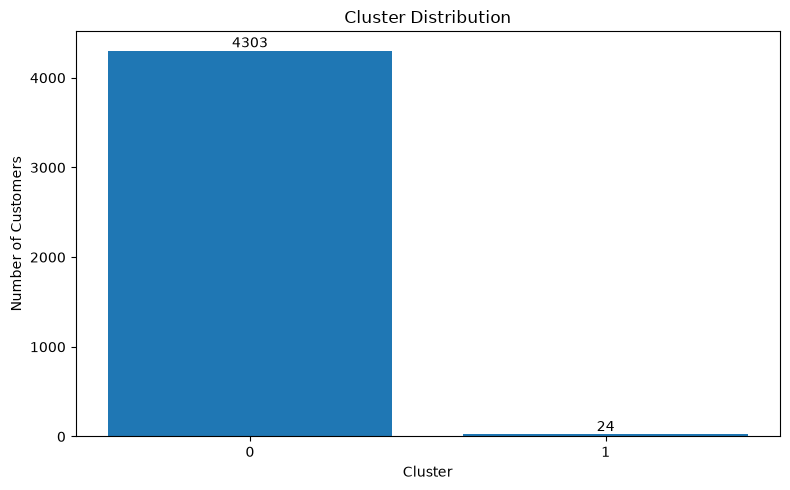

In [41]:
cluster_counts = result["cluster"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(cluster_counts.index, cluster_counts.values)

ax.set_title("Cluster Distribution")
ax.set_xlabel("Cluster")
ax.set_ylabel("Number of Customers")
ax.set_xticks(cluster_counts.index)

for i, count in enumerate(cluster_counts):
    ax.text(i, count, str(count), ha="center", va="bottom")

plt.tight_layout()
fig.savefig(FIGURES_DIR / "kmeans_cluster_distribution.png", dpi=300)
plt.show()

## RFM theo từng cụm

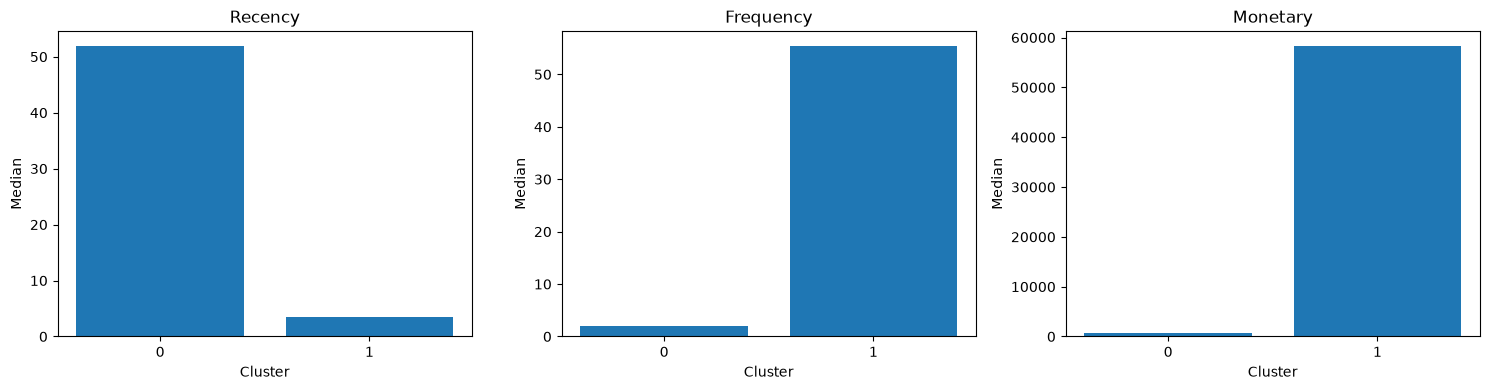

In [42]:
rfm = result.groupby("cluster")[FEATURE_A].median()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, feature in zip(axes, FEATURE_A):
    ax.bar(rfm.index, rfm[feature])
    ax.set_title(feature)
    ax.set_xlabel("Cluster")
    ax.set_ylabel("Median")
    ax.set_xticks(rfm.index)

plt.tight_layout()
fig.savefig(FIGURES_DIR / "kmeans_rfm_comparison.png", dpi=300)
plt.show()

In [43]:
for cluster_id, row in cluster_medians.iterrows():
    count = int(cluster_count.loc[cluster_id])
    display(Markdown(
        f"**Cụm {cluster_id}:** {count:,} khách ({count / len(labels):.2%}); "
        f"trung vị R={row['Recency']:.2f} ngày, F={row['Frequency']:.2f} hóa đơn, "
        f"M={row['Monetary']:.2f} GBP."
    ))
display(Markdown(
    "R thấp biểu thị mua gần đây hơn; F và M cao biểu thị mua thường xuyên và "
    "chi tiêu lịch sử cao hơn. Nhãn cụm chỉ là mã định danh, không phải thứ hạng. "
    "Cần đối chiếu cả ba đặc trưng và quy mô cụm trước khi đặt tên nghiệp vụ như VIP; "
    "Monetary không phải lợi nhuận hoặc giá trị tương lai."
))

**Cụm 0:** 4,303 khách (99.45%); trung vị R=52.00 ngày, F=2.00 hóa đơn, M=655.58 GBP.

**Cụm 1:** 24 khách (0.55%); trung vị R=3.50 ngày, F=55.50 hóa đơn, M=58396.28 GBP.

R thấp biểu thị mua gần đây hơn; F và M cao biểu thị mua thường xuyên và chi tiêu lịch sử cao hơn. Nhãn cụm chỉ là mã định danh, không phải thứ hạng. Cần đối chiếu cả ba đặc trưng và quy mô cụm trước khi đặt tên nghiệp vụ như VIP; Monetary không phải lợi nhuận hoặc giá trị tương lai.

## Lưu pipeline và kiểm tra nạp lại

`kmeans_model.pkl` chứa Pipeline đã fit (scaler → PCA → K-Means). Đầu vào dự đoán là DataFrame RFM gốc theo FEATURE_A, không chuẩn hóa lần nữa.

In [44]:
final_metrics = {
    'Silhouette': silhouette_score(X_pca, labels),
    'DBI': davies_bouldin_score(X_pca, labels),
    'CHI': calinski_harabasz_score(X_pca, labels),
    'Inertia': model.inertia_,
}
for name, value in final_metrics.items():
    print(f'{name}: {value:.6f}')
    assert np.isclose(value, best_row[name]), f'{name} không khớp vòng khảo sát.'

# Các thành phần đã fit; không gọi fit lần nữa.
pipeline = Pipeline([('scaler', scaler), ('pca', pca_features), ('kmeans', model)])
model_path = BASE_DIR / 'kmeans_model.pkl'
joblib.dump(pipeline, model_path)
loaded_pipeline = joblib.load(model_path)
assert np.array_equal(loaded_pipeline.predict(X), labels), 'Nạp lại không tái lập được nhãn.'
with (BASE_DIR / 'kmeans_PCA_params.json').open('w', encoding='utf-8') as f:
    json.dump({
        'features': FEATURE_A,
        'scaling': 'StandardScaler',
        'pca': {'n_components': n_components, 'variance_threshold': threshold,
                'explained_variance_ratio': pca_features.explained_variance_ratio_.tolist()},
        'kmeans': model.get_params(),
        'selection': 'max Silhouette on X_pca among surveyed k',
        'metrics': final_metrics,
    }, f, ensure_ascii=False, indent=4)
print('Đã lưu pipeline và kiểm tra nhãn sau khi nạp lại khớp hoàn toàn.')

Silhouette: 0.899359
DBI: 0.727462
CHI: 1947.521834
Inertia: 8950.598577
Đã lưu pipeline và kiểm tra nhãn sau khi nạp lại khớp hoàn toàn.
